In [1]:
from google.colab import files
uploaded = files.upload()

Saving flower.jpg to flower.jpg


In [3]:
import cv2 as cv                  # OpenCV for image processing
import numpy as np                # NumPy for arrays and matrix operations
import matplotlib.pyplot as plt   # Matplotlib for displaying images and graphs

# Load the image
image_path = 'flower.jpg'
img = cv.imread(image_path)

# Check if the image was loaded successfully
if img is None:
    raise FileNotFoundError(f"Error: Image '{image_path}' not found. Please check the filename!")

print("Image loaded successfully!")
print("Image Shape (Height, Width, Channels):", img.shape)
print("Data Type:", img.dtype)

Image loaded successfully!
Image Shape (Height, Width, Channels): (1024, 1024, 3)
Data Type: uint8


In [17]:
height, width, channels = img.shape
print(f"Height: {height}, Width: {width}, Channels: {channels}")

# Get top-left and center pixel values using row/column indexing
top_left_pixel = img[0, 0]
center_pixel = img[height // 2, width // 2]

print("Top-Left Pixel (BGR):", top_left_pixel)
print("Center Pixel (BGR):", center_pixel)
print("Global Minimum:", img.min(), "Global Maximum:", img.max())
print("Per-Channel Min:", img.min(axis=(0, 1)))
print("Per-Channel Max:", img.max(axis=(0, 1)))

Height: 1024, Width: 1024, Channels: 3
Top-Left Pixel (BGR): [ 67 121  91]
Center Pixel (BGR): [ 27   3 167]
Global Minimum: 0 Global Maximum: 255
Per-Channel Min: [ 0  0 27]
Per-Channel Max: [249 255 255]


Center Pixel RGB: [167   3  27]
Center Pixel HEX Value: #a7031b


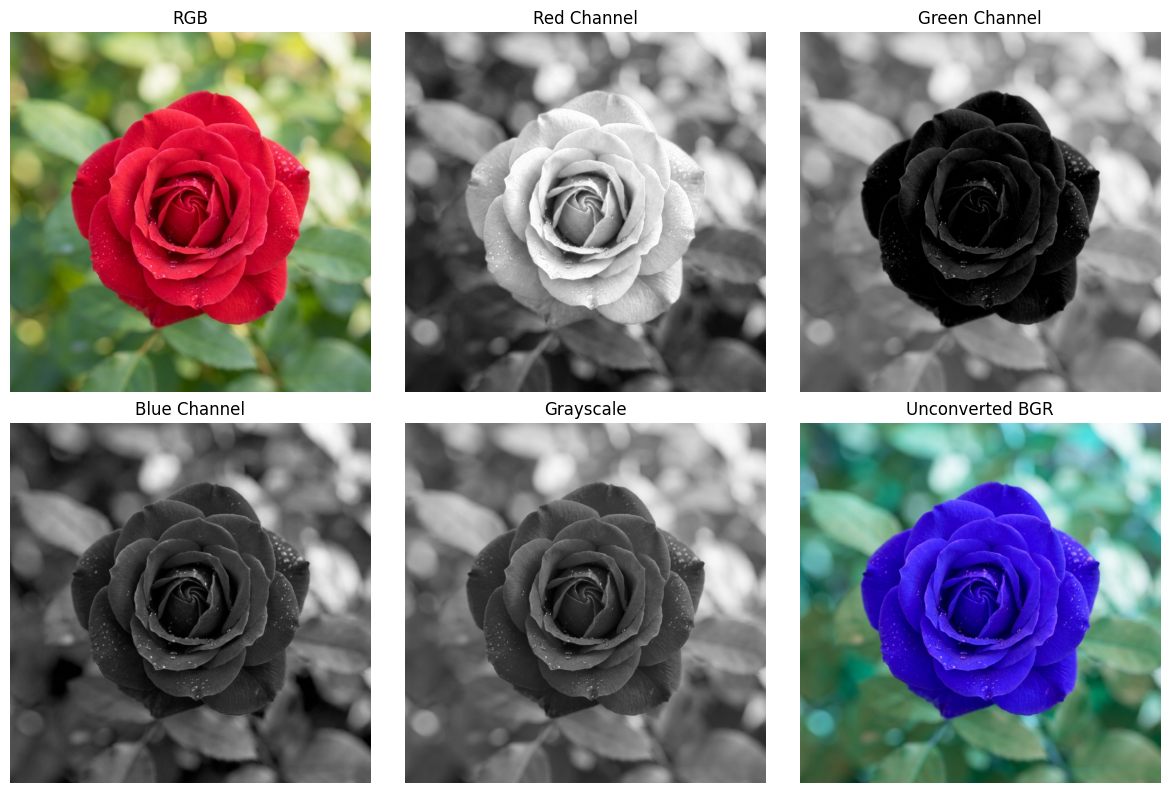

In [13]:
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# OpenCV loads image in BGR format -> index 0=Blue, 1=Green, 2=Red
b_channel, g_channel, r_channel = cv.split(img)

# Center pixel RGB value and HEX conversion
center_rgb = img_rgb[height // 2, width // 2]
hex_val = '#{:02x}{:02x}{:02x}'.format(*center_rgb)
print("Center Pixel RGB:", center_rgb)
print("Center Pixel HEX Value:", hex_val)

# Display 2 x 3 Grid containing all 6 views correctly labeled
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(img_rgb)
plt.title("RGB")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(r_channel, cmap="gray")
plt.title("Red Channel")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(g_channel, cmap="gray")
plt.title("Green Channel")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(b_channel, cmap="gray")
plt.title("Blue Channel")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(img_gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(img)
plt.title("Unconverted BGR")
plt.axis("off")

plt.tight_layout()
plt.show()

Crop Region Shape: (100, 100, 3)


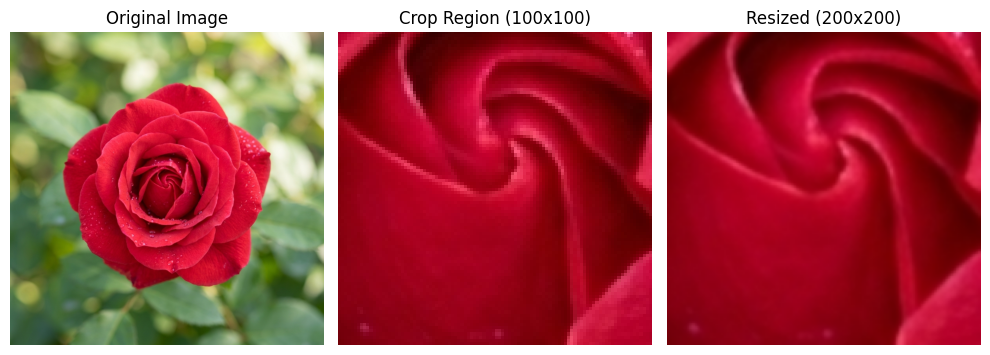

File saved successfully?: True


In [14]:
# Center coordinates par exact 100 x 100 region crop karna (phool ke markaz se)
y_start, y_end = (height // 2) - 50, (height // 2) + 50
x_start, x_end = (width // 2) - 50, (width // 2) + 50

# Agar phool thora ooper ya neechay ho toh indices ko yahan adjust kiya ja sakta hai
crop_img = img_rgb[y_start:y_end, x_start:x_end]
print("Crop Region Shape:", crop_img.shape)

# Crop ko 200 x 200 pixels mein resize karna
resized_crop = cv.resize(crop_img, (200, 200))

# Original, Crop, aur Resized images ko side-by-side display karna
plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(crop_img)
plt.title("Crop Region (100x100)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(resized_crop)
plt.title("Resized (200x200)")
plt.axis("off")

plt.tight_layout()
plt.show()

# Resized RGB image ko wapas BGR mein convert karke save karna
resized_crop_bgr = cv.cvtColor(resized_crop, cv.COLOR_RGB2BGR)
save_status = cv.imwrite("resized_crop.png", resized_crop_bgr)
print("File saved successfully?:", save_status)

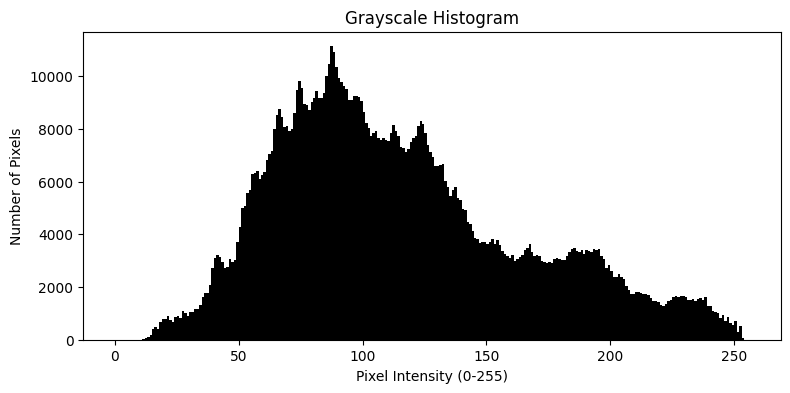

In [11]:
import cv2 as cv
import matplotlib.pyplot as plt

# Ensure the grayscale image is available
if 'img_gray' not in globals():
    if 'img' in globals():
        img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    else:
        img = cv.imread('flower.jpg')
        img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Generate the grayscale histogram
plt.figure(figsize=(9, 4))
plt.hist(img_gray.ravel(), bins=256, range=[0, 256], color='black')  #
plt.title('Grayscale Histogram')  #
plt.xlabel('Pixel Intensity (0-255)')  #[cite: 1]
plt.ylabel('Number of Pixels')  #[cite: 1]

# Save and display the histogram plot
plt.savefig('grayscale_histogram.png')  #[cite: 1]
plt.show()  #[cite: 1]

8-bit unique values: 256
4-bit unique values: 16
2-bit unique values: 4
1-bit unique values: 2


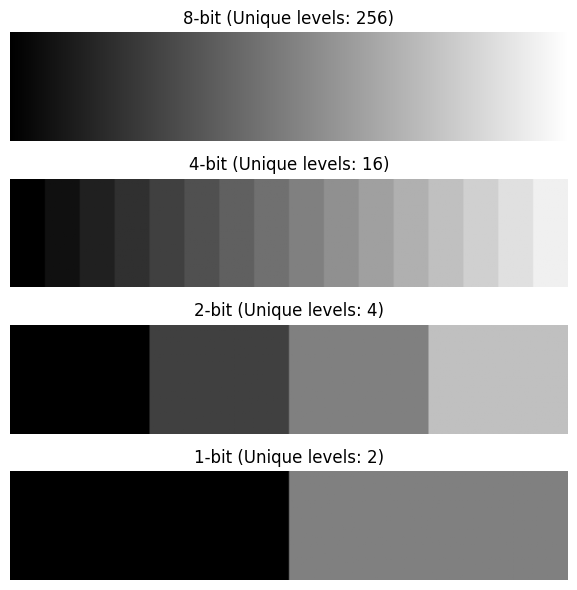

In [18]:
# Step 7: Bit-Depth Quantization & Demonstration
gradient = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (50, 1))
quant_4bit = (gradient // 16) * 16
quant_2bit = (gradient // 64) * 64
quant_1bit = (gradient // 128) * 128

# Print unique-value counts according to lab instructions
print("8-bit unique values:", np.unique(gradient).size)
print("4-bit unique values:", np.unique(quant_4bit).size)
print("2-bit unique values:", np.unique(quant_2bit).size)
print("1-bit unique values:", np.unique(quant_1bit).size)

# Plotting the figure and subplots
fig, axes = plt.subplots(4, 1, figsize=(8, 6))

axes[0].imshow(gradient, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("8-bit (Unique levels: 256)")
axes[0].axis('off')

axes[1].imshow(quant_4bit, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("4-bit (Unique levels: 16)")
axes[1].axis('off')

axes[2].imshow(quant_2bit, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("2-bit (Unique levels: 4)")
axes[2].axis('off')

axes[3].imshow(quant_1bit, cmap='gray', vmin=0, vmax=255)
axes[3].set_title("1-bit (Unique levels: 2)")
axes[3].axis('off')

plt.tight_layout()
plt.show()
